<a href="https://colab.research.google.com/github/Saketh-lab/geometric_tests_pythia/blob/main/Testing_Pythia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "transformer_lens<4.0"


In [ ]:
import torch
from transformer_lens import HookedTransformer

model = HookedTransformer.from_pretrained("pythia-70m")
model.eval()

print(f"layers: {model.cfg.n_layers}, d_model: {model.cfg.d_model}")

/tmp/ipykernel_5918/3829123531.py:4: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("pythia-70m")


config.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  166MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

Loaded pretrained model pythia-70m into HookedTransformer
layers: 6, d_model: 512


In [ ]:
sentences = [
    "The quick brown fox jumps over the lazy dog.",
    "Paris is the capital of France.",
    "She sells seashells by the seashore.",
    "The stock market crashed yesterday afternoon.",
    "Quantum mechanics describes subatomic particles.",
    "He ran quickly to catch the departing train.",
    "The chef prepared a delicious three course meal.",
    "Scientists discovered a new exoplanet last week.",
]

In [ ]:
import numpy as np

n_layers = model.cfg.n_layers
layer_acts = {l: [] for l in range(n_layers)}

with torch.no_grad():
    for s in sentences:
        tokens = model.to_tokens(s)
        _, cache = model.run_with_cache(tokens)
        for l in range(n_layers):
            resid = cache["resid_post", l][0, -1, :]  # last token, after layer l
            layer_acts[l].append(resid.cpu().numpy())

layer_matrices = {l: np.stack(layer_acts[l]) for l in range(n_layers)}
print(layer_matrices[0].shape)  # should print (8, 512)

(8, 512)


In [ ]:
import numpy as np

n_layers = model.cfg.n_layers
layer_acts = {l: [] for l in range(n_layers)}

with torch.no_grad():
    for s in sentences:
        tokens = model.to_tokens(s)
        _, cache = model.run_with_cache(tokens)
        for l in range(n_layers):
            resid = cache["resid_post", l][0, -1, :]  # last token, after layer l
            layer_acts[l].append(resid.cpu().numpy())

# stack into one matrix per layer: shape (n_sentences, d_model)
layer_matrices = {l: np.stack(layer_acts[l]) for l in range(n_layers)}
print(layer_matrices[0].shape)  # should print (8, 512)

(8, 512)


In [ ]:
def mean_cosine_sim(X):
    Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
    sim = Xn @ Xn.T
    n = sim.shape[0]
    off_diag = sim[~np.eye(n, dtype=bool)]
    return off_diag.mean()

for l in range(n_layers):
    print(f"layer {l}: mean cosine sim = {mean_cosine_sim(layer_matrices[l]):.4f}")

layer 0: mean cosine sim = 0.9740
layer 1: mean cosine sim = 0.9967
layer 2: mean cosine sim = 0.9999
layer 3: mean cosine sim = 0.9998
layer 4: mean cosine sim = 0.9991
layer 5: mean cosine sim = 0.9913


In [ ]:
def participation_ratio(X):
    Xc = X - X.mean(axis=0, keepdims=True)
    cov = np.cov(Xc.T)
    eigvals = np.linalg.eigvalsh(cov)
    eigvals = np.clip(eigvals, 0, None)
    return (eigvals.sum() ** 2) / (np.sum(eigvals ** 2) + 1e-12)

for l in range(n_layers):
    print(f"layer {l}: PR = {participation_ratio(layer_matrices[l]):.2f} / {model.cfg.d_model}")

layer 0: PR = 3.73 / 512
layer 1: PR = 2.26 / 512
layer 2: PR = 1.52 / 512
layer 3: PR = 1.80 / 512
layer 4: PR = 2.75 / 512
layer 5: PR = 5.25 / 512


In [ ]:
def effective_rank(X):
    Xc = X - X.mean(axis=0, keepdims=True)
    cov = np.cov(Xc.T)
    eigvals = np.linalg.eigvalsh(cov)
    eigvals = np.clip(eigvals, 1e-12, None)
    p = eigvals / eigvals.sum()
    entropy = -np.sum(p * np.log(p))
    return np.exp(entropy)

for l in range(n_layers):
    print(f"layer {l}: effective rank = {effective_rank(layer_matrices[l]):.2f} / {model.cfg.d_model}")

layer 0: effective rank = 4.94 / 512
layer 1: effective rank = 3.45 / 512
layer 2: effective rank = 2.21 / 512
layer 3: effective rank = 2.73 / 512
layer 4: effective rank = 4.04 / 512
layer 5: effective rank = 5.99 / 512


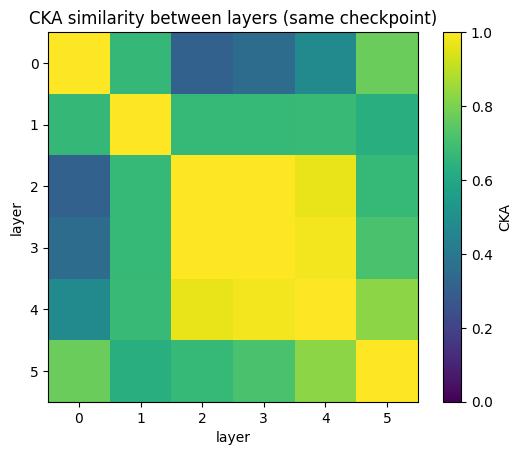

In [ ]:
def linear_cka(X, Y):
    Xc = X - X.mean(axis=0, keepdims=True)
    Yc = Y - Y.mean(axis=0, keepdims=True)
    gram_X = Xc @ Xc.T
    gram_Y = Yc @ Yc.T
    hsic = (gram_X * gram_Y).sum()
    norm_x = np.sqrt((gram_X * gram_X).sum())
    norm_y = np.sqrt((gram_Y * gram_Y).sum())
    return hsic / (norm_x * norm_y + 1e-12)

cka_matrix = np.zeros((n_layers, n_layers))
for i in range(n_layers):
    for j in range(n_layers):
        cka_matrix[i, j] = linear_cka(layer_matrices[i], layer_matrices[j])

import matplotlib.pyplot as plt
plt.imshow(cka_matrix, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="CKA")
plt.xlabel("layer"); plt.ylabel("layer")
plt.title("CKA similarity between layers (same checkpoint)")
plt.show()

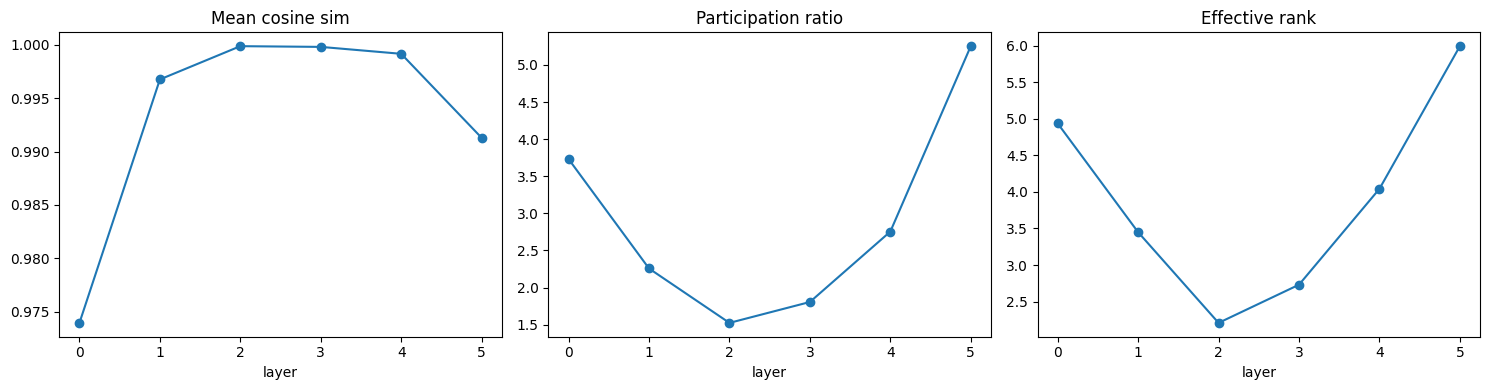

In [ ]:
cos_vals = [mean_cosine_sim(layer_matrices[l]) for l in range(n_layers)]
pr_vals  = [participation_ratio(layer_matrices[l]) for l in range(n_layers)]
er_vals  = [effective_rank(layer_matrices[l]) for l in range(n_layers)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(cos_vals, marker='o'); axes[0].set_title("Mean cosine sim")
axes[1].plot(pr_vals, marker='o'); axes[1].set_title("Participation ratio")
axes[2].plot(er_vals, marker='o'); axes[2].set_title("Effective rank")
for ax in axes: ax.set_xlabel("layer")
plt.tight_layout()
plt.show()